In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from Bio import SeqIO


pep_hits_long = pd.read_csv('long_091826.csv')


pep_hits = pd.read_csv('pep_hits_wo_taxa_to_remove_091826.csv')

In [2]:
denv = pep_hits_long[pep_hits_long['species'] == 'Orthoflavivirus denguei'].copy()

denv_hits= pep_hits[pep_hits['species'] == 'Orthoflavivirus denguei'].copy()

unique_denv_peptides = denv['sequence'].drop_duplicates()

## importing the reference sequences fetched from UniProt (P29991 · POLG_DEN27)

In [3]:
records = list(SeqIO.parse('UP_P29991_POLG_DEN27_DENV2_reference.fasta', 'fasta'))

for r in records:
    print(r.id, len(r.seq))

sp|P29991|POLG_DEN27 3391


In [4]:
print(denv['category'].value_counts())
print(denv['sequence'].nunique())
print(denv['protein_std'].unique())

category
Household contact    8864
Lassa survivor       3840
US healthy           2784
Name: count, dtype: int64
32
['polyprotein' 'polymerase']


## import PairwiseAligner and use BLOSUM62 matrix for local protein alignment

In [5]:
from Bio.Align import PairwiseAligner
from Bio.Align import substitution_matrices

aligner = PairwiseAligner()
aligner.mode = 'local' #want the peptide to find its best location within the reference

aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

## polyprotein

In [6]:
poly = str(next(r.seq for r in records if "sp|P29991|POLG_DEN27" in r.id))

In [7]:
ref = poly

In [8]:
ref

'MNDQRKEAKNTPFNMLKRERNRVSTVQQLTKRFSLGMLQGRGPLKLYMALVAFLRFLTIPPTAGILKRWGTIKKSKAINVLRGFRKEIGRMLNILNRRRRSAGMIIMLIPTVMAFHLTTRNGEPHMIVSRQEKGKSLLFKTEVGVNMCTLMAMDLGELCEDTITYKCPLLRQNEPEDIDCWCNSTSTWVTYGTCTTMGEHRREKRSVALVPHVGMGLETRTETWMSSEGAWKHVQRIETWILRHPGFTMMAAILAYTIGTTHFQRALILILLTAVTPSMTMRCIGMSNRDFVEGVSGGSWVDIVLEHGSCVTTMAKNKPTLDFELIKTEAKQPATLRKYCIEAKLTNTTTESRCPTQGEPSLNEEQDKRFVCKHSMVDRGWGNGCGLFGKGGIVTCAMFRCKKNMEGKVVQPENLEYTIVITPHSGEEHAVGNDTGKHGKEIKITPQSSITEAELTGYGTITMECSPRTGLDFNEIVLLQMENKAWLVHRQWFLDLPLPWLPGADTQGSNWIQKETLVTFKNPHAKKQDVVVLGSQEGAMHTALTGATEIQMSSGNLLFTGHLKCRLRMDKLQLKGMSYSMCTGKFKVVKEIAETQHGTIVIRVQYEGDGSPCKIPFEIMDLEKRHVLGRLITVNPIVTEKDSPVNIEAEPPFGDSYIIIGVEPGQLKLNWFKKGSSIGQMFETTMRGAKRMAILGDTAWDFGSLGGVFTSIGKALHQVFGAIYGAAFSGVSWTMKILIGVIITWIGMNSRSTSLSVTLVLVGIVTLYLGVMVQADSGCVVSWKNKELKCGSGIFITDNVHTWTEQYKFQPESPSKLASAIQKAHEEDICGIRSVTRLENLMWKQITPELNHILSENEVKLTIMTGDIKGIMQAGKRSLRPQPTELKYSWKTWGKAKMLSTESHNQTFFIDGPETAECPNTNRAWNSLEVEDYGFGVFTTNIWLKLKEKQDVFCDSKLMSAAIKDNRAVHADMGYWIESALNDTWKIEKASFIEVKNCH

## define mapping function -> keep local 

In [9]:
def map_peptide_to_reference(peptide, reference, aligner):
    """
    goal: map a peptide onto a reference protein. 

    output: returns a dictionary containing
    - alignment score
    - reference start/end (1-based)
    - reference positions covered by aligned peptide residues
    """

    #if no exact substring match, use local alignment
    alignment = aligner.align(reference, peptide)[0] #[0] to extract the first and best-scoring Alignment object from the results

    #aligner.align[0].aligned returns the start and end coordinates of the aligned segments for the target and query sequences
    ref_blocks, peptide_blocks = alignment.aligned

    ref_positions = []

    for (ref_start, ref_end), (pep_start, pep_end) in zip(ref_blocks, peptide_blocks):
        
        for i in range(ref_end - ref_start):
            ref_positions.append(ref_start + i + 1) #1-based

    #overall peptide coordinates
    pep_start = peptide_blocks[0][0] + 1
    pep_end = peptide_blocks[-1][1] #take the last block,so -1, in case there are more than one aligned blocks. and [1] for the end

    #total number of peptide residues included in the aligned blocks
    aligned_length = sum(end - start for start, end in peptide_blocks)

    #total number 

    return{
        'score': alignment.score, 
        'ref_start': ref_positions[0],
        'ref_end': ref_positions[-1],
        'ref_positions': ref_positions, 
        'pep_start' : pep_start, 
        'pep_end': pep_end,
        'aligned_length': aligned_length, 
        'fraction_aligned': aligned_length/ len(peptide)
    }


In [10]:
mapping = []

for peptide in unique_denv_peptides:
    result = map_peptide_to_reference(peptide, ref, aligner)

    mapping.append({
        'sequence': peptide, 
        'score': result['score'], 
        'ref_start': result['ref_start'], 
        'ref_end': result['ref_end'], 
        'ref_positions': result['ref_positions'], 
        'pep_start': result['pep_start'], 
        'pep_end': result['pep_end'], 
        'aligned_pep_length': result['aligned_length'], 
        'fraction_aligned': result['fraction_aligned']

    })

np_mapping = pd.DataFrame(mapping)

In [11]:
np_mapping['fraction_aligned'].describe()

count    32.000000
mean      0.984375
std       0.049768
min       0.717391
25%       0.978261
50%       1.000000
75%       1.000000
max       1.000000
Name: fraction_aligned, dtype: float64

In [12]:
#check the length of peptide alignment, should be ~46

np_mapping['alignment_length'] = np_mapping['ref_positions'].str.len()

np_mapping['alignment_length'].describe()

count    32.000000
mean     45.281250
std       2.289307
min      33.000000
25%      45.000000
50%      46.000000
75%      46.000000
max      46.000000
Name: alignment_length, dtype: float64

In [13]:
np_mapping.shape

(32, 10)

In [14]:
np_mapping.sort_values('ref_start')[['ref_start', 'ref_end']].drop_duplicates().head(10)

,ref_start,ref_end
21,116,161
5,415,459
6,576,621
7,599,644
12,629,661
0,944,989
16,945,990
2,1013,1058
28,1475,1519
22,1565,1610


In [15]:
np_mapping.sort_values('alignment_length').head(2)

,sequence,score,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,fraction_aligned,alignment_length
12,DETGVTQNGRLITANPVVTDKEKPVNIEAEPPFGESYIVIGAGEKA,149.0,629,661,"[629, 630, 631, 632, 633, 634, 635, 636, 637, ...",9,41,33,0.717391,33
7,TVLVQVEYEGTDAPCKIPFTTQDEKGVIQNGRLITANPIVTDKEKP,130.0,599,644,"[599, 600, 601, 602, 603, 604, 605, 606, 607, ...",1,46,45,0.978261,45


In [16]:
#inspect the shortest mappings: 
np_mapping.sort_values("alignment_length").head(2)

,sequence,score,ref_start,ref_end,ref_positions,pep_start,pep_end,aligned_pep_length,fraction_aligned,alignment_length
12,DETGVTQNGRLITANPVVTDKEKPVNIEAEPPFGESYIVIGAGEKA,149.0,629,661,"[629, 630, 631, 632, 633, 634, 635, 636, 637, ...",9,41,33,0.717391,33
7,TVLVQVEYEGTDAPCKIPFTTQDEKGVIQNGRLITANPIVTDKEKP,130.0,599,644,"[599, 600, 601, 602, 603, 604, 605, 606, 607, ...",1,46,45,0.978261,45


In [17]:
np_mapping = np_mapping.merge(pep_hits[['peptide', 'sensitivity', 'specificity', 'sequence']], on='sequence', how='left')

np_mapping.sort_values(['sensitivity'], ascending=False)[['ref_start', 'ref_end', 'sensitivity', 'peptide', 'sequence']].head(50)

,ref_start,ref_end,sensitivity,peptide,sequence
23,3314,3358,0.478589,WLD55688.1|polyprotein|dengue_virus_type_2|iso...,SWMEDKTPVTTWEDVPYLGKREDQWCGSLIGLTSRATWAQNILTAI
7,599,644,0.201511,AMN88556.1|polyprotein|Dengue_virus|isolate=Br...,TVLVQVEYEGTDAPCKIPFTTQDEKGVIQNGRLITANPIVTDKEKP
19,3059,3104,0.110831,WEG68663.1|polyprotein|dengue_virus_type_1|iso...,IFKLTYQNKVVRVQRPAKNGTVMDVISRRDQRGSGQVGTYGLNTFT
9,1771,1816,0.110831,AMN88556.1|polyprotein|Dengue_virus|isolate=Br...,ARGYISTRVGMGEAAAIFMTATPPGSAEAFPQSNSVIYDEEKDIPE
18,116,161,0.103275,UDI89630.1|polyprotein|dengue_virus_type_2|iso...,HLTTRNGEPHMIVSKNEKGKSLLFKTENGINMCTLMAMDLGELCED
22,1565,1610,0.103275,WEG68698.1|polyprotein|dengue_virus_type_2|iso...,KEGEEVQVLALEPGKNPRAVQTKPGTFKTNTGTIGAVSLDFSPGTS
24,2507,2551,0.100756,WMV06615.1|polyprotein|dengue_virus_type_1|iso...,RQLNQLSKSEFNTYKRSGITEVDRSEAKEGLKRGETTKHAVSRGTA
26,3014,3059,0.098237,WVW36851.1|polyprotein|dengue_virus_type_2|iso...,SKKEGGAMYADDTAGWDTRITLEDLKNEEMVTNHMEGEHKKLAEAI
31,1934,1979,0.095718,XQH47600.1|polyprotein|dengue_virus_type_4|iso...,GRIGRNPAQEDDQYVFSGDPLKNDEDHAHWTEAKMLLDNIYTPEGI
12,629,661,0.078086,ANC57592.1|polyprotein|dengue_virus_type_1|iso...,DETGVTQNGRLITANPVVTDKEKPVNIEAEPPFGESYIVIGAGEKA


In [18]:
np_mapping.sort_values(['ref_start'], ascending=True)[['ref_start', 'ref_end', 'sensitivity', 'peptide', 'sequence']].head(50)

,ref_start,ref_end,sensitivity,peptide,sequence
21,116,161,0.073048,WEG68698.1|polyprotein|dengue_virus_type_2|iso...,HLTTRNGEPHMIVGRQEKGKSLLFKTEDGVNMCTLMAIDLGELCED
18,116,161,0.103275,UDI89630.1|polyprotein|dengue_virus_type_2|iso...,HLTTRNGEPHMIVSKNEKGKSLLFKTENGINMCTLMAMDLGELCED
5,415,459,0.062972,AMN88556.1|polyprotein|Dengue_virus|isolate=Br...,LKYSVIVTVHTGDQHQVGNETTGHGTTATITPQAPTSEIQLTDYGA
6,576,621,0.075567,AMN88556.1|polyprotein|Dengue_virus|isolate=Br...,GMSYVMCTGSFKLKKEVAETQHGTVLVQVEYEGTDAPCKIPFTTQD
7,599,644,0.201511,AMN88556.1|polyprotein|Dengue_virus|isolate=Br...,TVLVQVEYEGTDAPCKIPFTTQDEKGVIQNGRLITANPIVTDKEKP
12,629,661,0.078086,ANC57592.1|polyprotein|dengue_virus_type_1|iso...,DETGVTQNGRLITANPVVTDKEKPVNIEAEPPFGESYIVIGAGEKA
0,944,989,0.052897,AFZ40120.1|polyprotein|dengue_virus_type_2|iso...,LRLREKQDVFCDSKLMSAAIKDNRAVHADMGYWIESALNDTWKIEK
16,945,990,0.062972,QVJ82483.1|polyprotein|dengue_virus_type_4|iso...,RFREGVSETCDHRLMAAAVKDQLAVHADMGYWIESAKNQTWQIEKA
2,1013,1058,0.050378,AFZ40123.1|polyprotein|dengue_virus_type_2|iso...,ESEMVIPKNFAGPVSQHNNRPGYYTQTAGPWHLGKLEMDFDFCEGT
28,1475,1519,0.052897,XLT96517.1|polyprotein|dengue_virus_type_3|iso...,RSGVLWDVPSPPETQKAELEEGVYRIKQQGILGKTQVGVGVQKDGV


## inspecting alignments which are shorter than expected aligned pep length being 45 instead of 46

In [19]:
short = np_mapping.sort_values("aligned_pep_length").head(3)

for _, row in short.iterrows():
    peptide = row["sequence"]

    alignment = aligner.align(ref, peptide)[0]

    print("\n" + "=" * 80)
    print(peptide)
    print(alignment)


DETGVTQNGRLITANPVVTDKEKPVNIEAEPPFGESYIVIGAGEKA
target          628 GRLITVNPIVTEKDSPVNIEAEPPFGDSYIIIG 661
                  0 |||||.||.||.|..|||||||||||.|||.||  33
query             8 GRLITANPVVTDKEKPVNIEAEPPFGESYIVIG  41


TVLVQVEYEGTDAPCKIPFTTQDEKGVIQNGRLITANPIVTDKEKP
target          598 TIVIRVQYEGDGSPCKIPFEIMDLEKRHVL-GRLITVNPIVTEKDSP 644
                  0 |....|.|||...||||||...|-||....-|||||.|||||.|..|  47
query             0 TVLVQVEYEGTDAPCKIPFTTQD-EKGVIQNGRLITANPIVTDKEKP  46


GSPIVNRDGKVVGLYGNGVVTTSGTYVSAIAQSKVSQEGPLPEIED
target         1610 GSPIIDKKGKVVGLYGNGVVTRSGAYVSAIAQTEKSIEDN-PEIED 1655
                  0 ||||....|||||||||||||.||.|||||||...|.|..-|||||   46
query             0 GSPIVNRDGKVVGLYGNGVVTTSGTYVSAIAQSKVSQEGPLPEIED   46



## merging the mapping back to the individual-level dataframe


In [20]:
np = denv.merge(np_mapping, on='sequence', how='left')

In [21]:
np.shape

(15488, 25)

## .explode() turns one peptide/individual row to one row per amino-acid position covered by that peptide

In [22]:
np_residues = np.explode('ref_positions').rename(columns={'ref_positions': 'position'})

## keep only reactive peptides

In [23]:
reactive_residues = np_residues[np_residues['reactive']].copy()

## now we have the people and amino acid positions at which they have nucleoprotein antibody reactivity. But we need to remove contributions to the same amino-acid position. each individual can contribute at most one to a given amino acid position. 

In [24]:
reactive_residues = reactive_residues[['individual', 'cohort', 'category', 'position']].drop_duplicates()

## calculate number of individuals in each category

In [26]:
group_sizes = (
    np[['individual', 'cohort', 'category']].drop_duplicates().groupby(['cohort', 'category']).size().rename('n_individuals').reset_index()
)

group_sizes

,cohort,category,n_individuals
0,HBDB,US healthy,87
1,SL,Household contact,277
2,SL,Lassa survivor,120


## now count reactive individuals at each position

In [27]:
position_counts = (
    reactive_residues.groupby(['cohort', 'category', 'position'])['individual'] #reactive residues only include SL individuals
    .nunique()
    .rename('n_seroreactive')
    .reset_index()
)

position_counts.head(2)

,cohort,category,position,n_seroreactive
0,SL,Household contact,116,48
1,SL,Household contact,117,48


In [28]:
position_summary = position_counts.merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary.head(2)

,cohort,category,position,n_seroreactive,n_individuals
0,SL,Household contact,116,48,277
1,SL,Household contact,117,48,277


In [29]:
position_summary['pct_seroreactive'] = (
    position_summary['n_seroreactive'] / position_summary['n_individuals'] * 100
)

In [42]:
position_summary[position_summary['position'].between(3314,3392)].head(20)

,cohort,category,position,n_seroreactive,pct_seroreactive,n_individuals
3313,SL,Household contact,3314,141.0,50.902527,277
3314,SL,Household contact,3315,141.0,50.902527,277
3315,SL,Household contact,3316,141.0,50.902527,277
3316,SL,Household contact,3317,141.0,50.902527,277
3317,SL,Household contact,3318,141.0,50.902527,277
3318,SL,Household contact,3319,141.0,50.902527,277
3319,SL,Household contact,3320,141.0,50.902527,277
3320,SL,Household contact,3321,141.0,50.902527,277
3321,SL,Household contact,3322,141.0,50.902527,277
3322,SL,Household contact,3323,141.0,50.902527,277


## add positions with zero seroreactivity 

In [31]:
all_positions = pd.DataFrame({'position': range(1, len(ref) + 1)}) #initiate a dataframe with one column

groups = np[['cohort', 'category']].drop_duplicates()

complete_grid = groups.merge(all_positions, how='cross')

complete_grid.head(2)

,cohort,category,position
0,SL,Household contact,1
1,SL,Household contact,2


In [32]:
position_summary = complete_grid.merge(
    position_summary,
    on=["cohort", "category", "position"],
    how="left"
)

position_summary["n_seroreactive"] = (
    position_summary["n_seroreactive"]
    .fillna(0)
)

position_summary = position_summary.drop(columns='n_individuals').merge(group_sizes, on=['cohort', 'category'], how='left')

position_summary['pct_seroreactive'] = 100 * position_summary['n_seroreactive'] / position_summary['n_individuals']

In [33]:
round(position_summary['pct_seroreactive'].max(),2)

51.67

## Now going to plot the % of cohort/ category reactive to the amino acid positions of the nucleoprotein

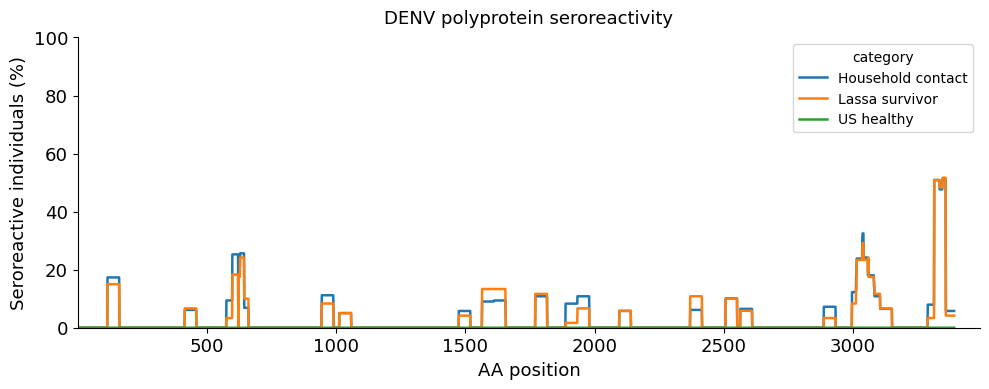

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 4))

sns.lineplot(
    data= position_summary, 
    x='position', 
    y='pct_seroreactive', 
    hue='category', 
    linewidth=1.8, 
    ax=ax
)

ax.set_xlabel('AA position', fontsize=13)
ax.set_ylabel('Seroreactive individuals (%)', fontsize=13)
ax.set_xlim(1, len(ref) + 100) #minimum and maximum position
ax.set_ylim(0,  100)

ax.tick_params(axis='x', labelsize=13)
ax.tick_params(axis='y', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines["right"].set_visible(False)

plt.title('DENV polyprotein seroreactivity', y=1.02, fontsize=13)
plt.tight_layout()
plt.rcParams['svg.fonttype'] = 'none'
plt.savefig('denv_polyprotein_reactivity.svg', format='svg')
plt.show()